In [1]:
import inspect
import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import statsmodels.api as sm

from Regression_utils import *
from PCA_utils import *
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler

In [2]:
main_df = pd.read_excel(r"C:\Users\jroland\East Texas Salt Water Disposal Company\Operations - Documents\Engineering\Disposal Wells\Workover Analysis\Derived All Data.xlsx")
print(main_df.columns)

Index(['Unnamed: 0.1', 'Unnamed: 0', 'Name', 'Year-Month', 'Hours',
       'Water Total', 'PSI', 'Revenue', 'Metered DM', 'Power Factor',
       'Billed DM', 'Billing KWH', 'Fuel Rate', 'Electrical Bill',
       'Workover Info', 'Workover Cost', 'Pump Model', 'Pump Number',
       'Plunger Size', 'Install Date', 'Maintenance Cost',
       'Maintenance Comments', 'Workover Count', 'Disposal Rate',
       'KWH per Barrel', 'Cost per KWH', 'Electrical Cost per Barrel',
       'Maintenance Cost per Barrel', 'Workover Cost per Barrel',
       'Revenue per Barrel', 'Income per Barrel', 'Income', 'Total Cost',
       'KWH/Water Ratio', 'Pump Age (years)', 'Workover Category',
       'Cumulative Electrical Cost', 'Cumulative Workover Cost',
       'Cumulative Maintenance Cost', 'Cumulative Total Cost',
       'Cumulative Income', 'Cumulative Revenue'],
      dtype='object')


In [3]:
# Double check that there are no problematic values for our data
print(main_df[main_df["PSI"].isna()])
print(np.isinf(main_df["PSI"]).sum())
print(main_df[main_df["Billing KWH"].isna()])
print(main_df["Billing KWH"].isna().sum())
print(np.isinf(main_df["Billing KWH"]).sum())

Empty DataFrame
Columns: [Unnamed: 0.1, Unnamed: 0, Name, Year-Month, Hours, Water Total, PSI, Revenue, Metered DM, Power Factor, Billed DM, Billing KWH, Fuel Rate, Electrical Bill, Workover Info, Workover Cost, Pump Model, Pump Number, Plunger Size, Install Date, Maintenance Cost, Maintenance Comments, Workover Count, Disposal Rate, KWH per Barrel, Cost per KWH, Electrical Cost per Barrel, Maintenance Cost per Barrel, Workover Cost per Barrel, Revenue per Barrel, Income per Barrel, Income, Total Cost, KWH/Water Ratio, Pump Age (years), Workover Category, Cumulative Electrical Cost, Cumulative Workover Cost, Cumulative Maintenance Cost, Cumulative Total Cost, Cumulative Income, Cumulative Revenue]
Index: []

[0 rows x 42 columns]
0
Empty DataFrame
Columns: [Unnamed: 0.1, Unnamed: 0, Name, Year-Month, Hours, Water Total, PSI, Revenue, Metered DM, Power Factor, Billed DM, Billing KWH, Fuel Rate, Electrical Bill, Workover Info, Workover Cost, Pump Model, Pump Number, Plunger Size, Install

<Axes: >

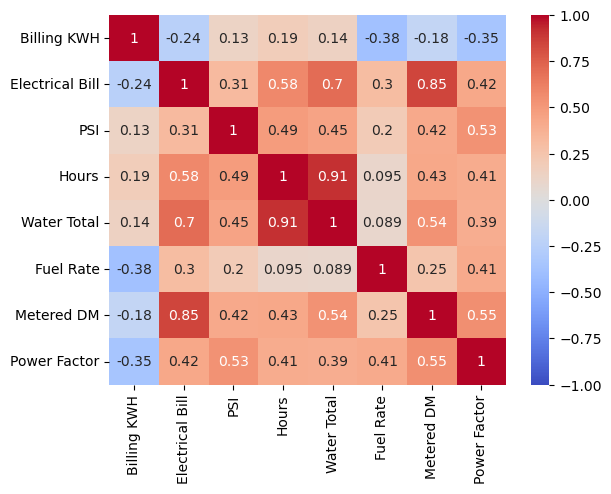

In [4]:
# basic correlation plot
corr_data = main_df[["Billing KWH", "Electrical Bill", "PSI", "Hours", "Water Total", "Fuel Rate", "Metered DM", "Power Factor"]]
corr_matrix = corr_data.corr()

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

In [4]:
exogs = ["PSI", "Billing KWH", "Hours", "Water Total", "Fuel Rate", "Metered DM", "Power Factor"]
endogs = ["Electrical Cost per Barrel"]
#endogs = ["Electrical Bill", "Billing KWH", "Water Total", "Metered DM", "Hours"]
os.chdir(r"C:\Users\jroland\East Texas Salt Water Disposal Company\Operations - Documents\Engineering\Disposal Wells\Workover Analysis\Graphs\Linear")
folder = os.getcwd()
folder = Path(folder)

lm_dict = datamine_ls(endogs, exogs, main_df)

In [5]:
write_ls_summaries(lm_dict, input_path=os.getcwd())

FileNotFoundError: [Errno 2] No such file or directory: 'C:\\Users\\jroland\\East Texas Salt Water Disposal Company\\Operations - Documents\\Engineering\\Disposal Wells\\Workover Analysis\\Graphs\\Linear\\Electrical Cost per Barrel vs PSI, Billing KWH, Hours, Water Total, Fuel Rate, Metered DM, Power Factor (OLS) predicted.pdf'

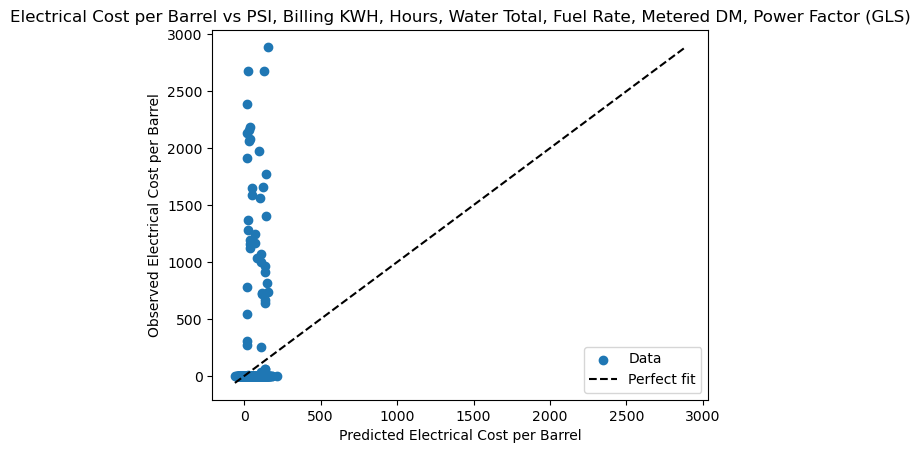

In [6]:
# Plot the relationships which can be visualized
# and plot the residuals for all relationships.
for label, lm in lm_dict.items():
    plot_ls(lm, os.getcwd())
    

In [8]:
# Standard Linear Regression
# PREDICTIVE
# Exploration of KWH and billing relationships
# Variables of interest: Predictors: Hours, Water Total, PSI, Metered DM, Power Factor, Billed DM, Fuel Rate
#                        Predicted: Billing KWH
predictors = ["Hours", "Water Total", "PSI", "Metered DM", "Power Factor", "Billed DM", "Fuel Rate"]
predicted = ["Billing KWH",]

# We need to split dataset based on time, rather than randomly. The last observation for the data is September 2025.
# Let's attempt to predict 6 months worth of data, so the training set will be start -> March 2025
X = main_df[predictors]
y = main_df[predicted]

print(main_df["Year-Month"])

train_X = main_df[main_df["Year-Month"] < "2025-04"]
train_X = train_X[predictors]

test_X = main_df[main_df["Year-Month"] >= "2025-04"]
test_X = test_X[predictors]

train_y = main_df[main_df["Year-Month"] < "2025-04"]
train_y = train_y[predicted]

test_y = main_df[main_df["Year-Month"] >= "2025-04"]
test_y = test_y[predicted]


# Normalization - NOTE: We are explaining rather than predicting in this case, so normalization should transform
#                       all data and not just the training data whose values are applied to the test data.
# NOTE: Normalization applies to PCA and other methods sensitive to absolute magnitude differences. 
#       OLS linear regression is not one of those.

0       2017-08
1       2017-09
2       2017-10
3       2017-11
4       2017-12
         ...   
8521    2025-05
8522    2025-06
8523    2025-07
8524    2025-08
8525    2025-09
Name: Year-Month, Length: 8526, dtype: object


In [ ]:
# Principle Components Analysis
"""
PCA on well-month attributes from "All Data With Workover Categories.xlsx".
 
Usage:
    python well_pca.py "All Data With Workover Categories.xlsx" [output_dir]
 
What it does
  1. Loads the sheet (one row per well per month).
  2. Picks the continuous operating attributes as PCA inputs.
     IDs, dates and free text (Name, Year-Month, Pump Number, Install Date,
     Maintenance Comments, unnamed index columns) are not attributes.
  3. Cleans obvious data errors (power factor > 100%), clips each column to its
     0.5th-99.5th percentile so a few bad readings can't dominate, fills the
     remaining gaps with the column median, then standardizes (z-scores).
  4. Fits PCA and writes explained variance, loadings and per-row scores.
  5. Treats sparse / categorical columns as *supplementary*: they are not used
     to build the components, but are projected afterwards so you can see where
     they sit (workover category, workover/maintenance cost, pump model,
     plunger size, pump age).
"""
 
# variables used to build principal components
pca_vars = [
    "Hours", "Water Total", "PSI", "Revenue", "Disposal Rate",
    "Metered DM", "Billed DM", "Power Factor", "Billing KWH",
    "Fuel Rate", "Electrical Bill",
]

# variables not used in fitting PCA, but tested against
non_pca_vars = ["Workover Cost", "Maintenance Cost", "Workover Count",
                "Plunger Size", "Pump Age (yrs)"]
 

out_path = Path(out_dir)
out_path.mkdir(parents=True, exist_ok=True)

# Clean data
X = filter_extremes(X)

# Run PCA - dict contains pca scores, variance dataframe, loadings dataframe, and scores dataframe
pca_dict = run_pca(X)

for cat in ["Workover Category", "Pump Model"]:
    g = score_df.groupby(cat, dropna=False)[pcs[:4]].agg(["mean"]).round(2)
    g.columns = pcs[:4]
    g.insert(0, "n_rows", score_df.groupby(cat, dropna=False).size())
    g.to_csv(out / f"pca_mean_scores_by_{cat.replace(' ', '_').lower()}.csv")
    print(f"Mean PC scores by {cat}:")
    print(g.to_string(), "\n")

# ---- per-well average scores ----
well = score_df.groupby("Name")[pcs[:4]].mean().round(3)
well.to_csv(out / "pca_mean_scores_by_well.csv")

# ---- plots ----
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(pcs, ev["explained_var_ratio"], color="#4C72B0", label="per component")
ax.plot(pcs, ev["cumulative"], color="#DD8452", marker="o", label="cumulative")
ax.set_ylabel("Share of variance"); ax.set_title("Scree plot"); ax.legend()
plt.xticks(rotation=45); fig.tight_layout(); fig.savefig(out / "pca_scree.png", dpi=150)

fig, ax = plt.subplots(figsize=(7, 6))
is_wo = score_df["Workover Category"] != "None"
ax.scatter(score_df.loc[~is_wo, "PC1"], score_df.loc[~is_wo, "PC2"],
           s=4, alpha=0.25, color="#999999", label="well-month")
for cat, sub in score_df[is_wo].groupby("Workover Category"):
    ax.scatter(sub["PC1"], sub["PC2"], s=30, label=f"workover: {cat}")
scale = np.abs(scores[:, :2]).max() / np.abs(loadings.iloc[:, :2].values).max() * 0.6
for attr, (l1, l2) in loadings.iloc[:, :2].iterrows():
    ax.arrow(0, 0, l1 * scale, l2 * scale, color="black", width=0.01, head_width=0.12)
    ax.text(l1 * scale * 1.1, l2 * scale * 1.1, attr, fontsize=8)
ax.set_xlabel(f"PC1 ({ev.iloc[0, 1]:.0%})"); ax.set_ylabel(f"PC2 ({ev.iloc[1, 1]:.0%})")
ax.set_title("PCA biplot"); ax.legend(fontsize=7, loc="best")
fig.tight_layout(); fig.savefig(out / "pca_biplot.png", dpi=150)
print(f"Outputs written to {out.resolve()}")


# Principle Components Regression 